# ALHIC2501 DC section anomalies
Compare measured scan endpoints, fractional depth and reconstructed table position. Track middles use the median of unflagged 1 cm bins from 35–65% of the measured length. Bands show approximate pointwise 95% intervals across sections. Side labels refer to the lowest and highest retained transverse table coordinates.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'data/metadata.csv').exists())
figdir = root/'figures/alhic2501_dc'
figdir.mkdir(parents=True, exist_ok=True)
meta = pd.read_csv(root/'data/metadata.csv').query("core=='ALHIC2501' and face=='w1' and ACorDC=='DC'").drop_duplicates('section')

In [2]:
tracks, audit = [], []
for r in meta.itertuples():
    name = f'ALHIC2501-{r.section}-w1-DC.csv'
    path = root/'data/clean/ALHIC2501'/name
    if not path.exists():
        path = root/'data/not-cleaned/ALHIC2501'/name
    data = pd.read_csv(path).rename(columns={'True_depth(m)':'depth','Y_dimension(mm)':'y','Button':'button'})
    top, bottom = data.depth.min(), data.depth.max()
    # Index depth in metres, relative index in cm, raw table coordinates in mm.
    def table_x(depth):
        return r.idx1_raw + (depth-r.idx_abs)*1000 - float(r.idx1_rel)*10
    bounds = data.groupby('y').depth.agg(['min','max','first','last'])
    bounds = bounds.loc[(bottom-top)-(bounds['max']-bounds['min']) <= 0.01]
    for rank,(y,b) in enumerate(bounds.iterrows()):
        t = data.loc[data.y==y].copy()
        keep = t.get('surface_imperfection', t.button).eq(0)
        # Bin by measured section depth so cross-track contrasts compare the same ice.
        t['bin'] = np.floor((t.depth-top)*100+1e-8).astype(int)
        v = t[keep].groupby('bin').agg(current=('meas','median'), depth=('depth','mean'))
        v['fraction'] = (v.depth-top)/(bottom-top)
        ref = v.loc[v.fraction.between(.35,.65),'current'].median()
        audit.append((r.section,rank,y,len(bounds),table_x(b['max'])-r.xmax,table_x(b['min'])-r.xmin,
                      b['first']>b['last'],ref,table_x(b['max']),bottom-top))
        if not np.isfinite(ref) or ref<=0:
            continue
        v['anomaly'] = 100*(v.current/ref-1)
        v['bottom'] = bottom-v.depth
        v['top'] = v.depth-top
        v['start'] = b['max']-v.depth
        v['table'] = table_x(v.depth)/1000
        v['side'] = 'low Y' if rank==0 else 'high Y' if rank==len(bounds)-1 else 'interior'
        tracks.append(v.assign(section=r.section,rank=rank).reset_index())
df = pd.concat(tracks,ignore_index=True)
audit = pd.DataFrame(audit,columns=['section','rank','y','n','deep_error_mm','shallow_error_mm','deep_first','reference','deep_table_mm','length_m'])
print(audit.describe().round(3).to_string(), '\nDeep first:', audit.deep_first.value_counts().to_dict())
print('Sections with valid references:',df.section.nunique(), 'tracks:',df.groupby(['section','rank']).ngroups)

           rank         y         n  deep_error_mm  shallow_error_mm  reference  deep_table_mm  length_m
count  1117.000  1117.000  1117.000         1117.0          1117.000     1101.0       1117.000  1117.000
mean      2.488   134.505     5.976           -0.0             1.415        0.0        994.802     0.966
std       1.717    19.871     0.402            0.0             0.142        0.0         99.095     0.114
min       0.000    69.813     3.000           -0.0             1.063        0.0        566.603     0.479
25%       1.000   120.279     6.000           -0.0             1.318        0.0        948.763     0.927
50%       2.000   134.638     6.000           -0.0             1.428        0.0       1010.162     0.993
75%       4.000   149.708     6.000            0.0             1.520        0.0       1062.500     1.033
max       6.000   174.457     7.000            0.0             1.739        0.0       1184.191     1.147 
Deep first: {True: 1117}
Sections with valid reference

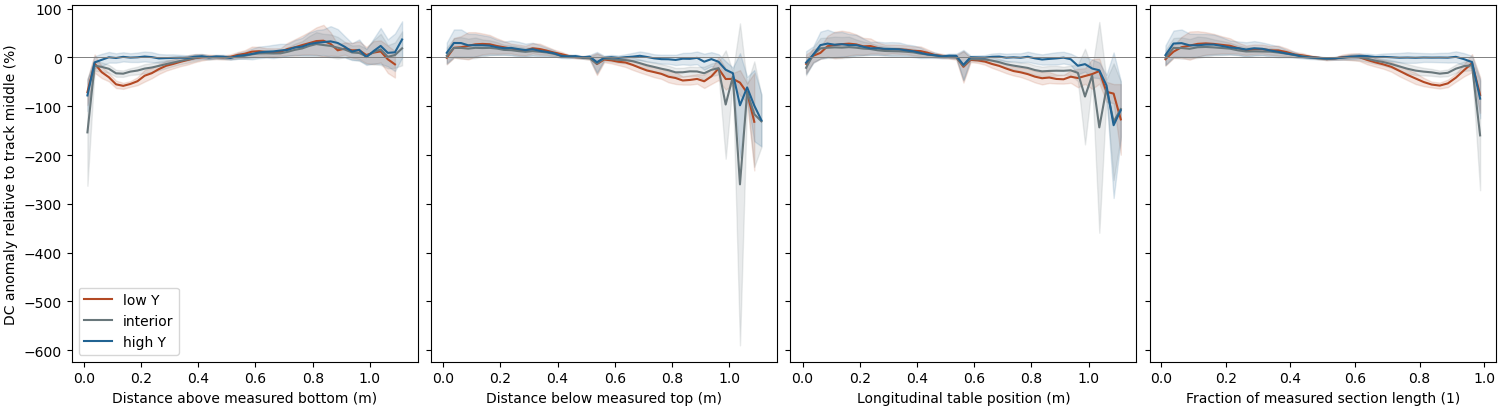

In [3]:
coords = {'bottom':('Distance above measured bottom (m)',.025),'top':('Distance below measured top (m)',.025),
          'table':('Longitudinal table position (m)',.025),'fraction':('Fraction of measured section length (1)',.025)}
def stack(frame,key,groups):
    width = coords[key][1]
    return frame.assign(position=(np.floor(frame[key]/width)+.5)*width).groupby(
        ['section','position',*groups],as_index=False).anomaly.mean()

fig, axes = plt.subplots(1,4,figsize=(15,4.1),sharey=True,layout='constrained')
for ax,(key,(label,width)) in zip(axes,coords.items()):
    for side,color in [('low Y','#b34924'),('interior','#69777b'),('high Y','#216392')]:
        sample = stack(df[df.side==side],key,[]).groupby('position').anomaly.agg(['mean','sem','count'])
        sample = sample[sample['count']>=10]
        ax.plot(sample.index,sample['mean'],label=side,color=color)
        ax.fill_between(sample.index,sample['mean']-1.96*sample['sem'],sample['mean']+1.96*sample['sem'],color=color,alpha=.14)
    ax.axhline(0,color='0.5',lw=.7)
    ax.set_xlabel(label)
axes[0].set_ylabel('DC anomaly relative to track middle (%)')
axes[0].legend()
fig.savefig(figdir/'section_profiles.png',dpi=180)
plt.show()

In [4]:
# Paired outer tracks at matching depth bins. Each section contributes one window average.
edges = df[df.side!='interior'].pivot_table(index=['section','bin'],columns='side',values='anomaly').dropna()
locations = df.groupby(['section','bin'])[['bottom','top','table','fraction']].mean()
paired = edges.join(locations)
paired['anomaly'] = paired['low Y']-paired['high Y']
for lo,hi in [(0,.03),(.03,.10),(.10,.20),(.20,.35),(.35,.50)]:
    g = paired[paired.bottom.between(lo,hi,inclusive='left')].groupby('section')[['low Y','high Y','anomaly']].mean()
    print(lo,hi,len(g),g.mean().round(2).to_dict(), 'paired median',round(g.anomaly.median(),2),
          'negative pairs',int((g.anomaly<0).sum()),'paired 95% half-width',round(1.96*g.anomaly.sem(),2))

0 0.03 148 {'low Y': -63.98, 'high Y': -60.03, 'anomaly': -3.95} paired median -1.6 negative pairs 86 paired 95% half-width 8.5
0.03 0.1 165 {'low Y': -27.68, 'high Y': -2.67, 'anomaly': -25.01} paired median -22.67 negative pairs 131 paired 95% half-width 7.13
0.1 0.2 165 {'low Y': -52.9, 'high Y': -0.35, 'anomaly': -52.55} paired median -49.56 negative pairs 153 paired 95% half-width 8.15
0.2 0.35 177 {'low Y': -21.85, 'high Y': 0.43, 'anomaly': -22.28} paired median -17.25 negative pairs 149 paired 95% half-width 6.92
0.35 0.5 174 {'low Y': -0.7, 'high Y': 1.08, 'anomaly': -1.78} paired median -1.42 negative pairs 105 paired 95% half-width 3.13


In [5]:
# Leave one section out. Predict the low-minus-high contrast from each coordinate alone.
# Use identical observations and require at least 10 independent training sections per bin.
def compare(frame):
    predictions = {}
    for key in coords:
        p = stack(frame,key,[])
        stats = p.groupby('position').anomaly.agg(['sum','count'])
        p = p.join(stats,on='position')
        p['pred'] = ((p['sum']-p.anomaly)/(p['count']-1)).where(p['count']>10)
        pos = (np.floor(frame[key]/coords[key][1])+.5)*coords[key][1]
        predictions[key] = p.set_index(['section','position']).pred.reindex(
            pd.MultiIndex.from_arrays([frame.section,pos])).to_numpy()
    pred = pd.DataFrame(predictions,index=frame.index).dropna()
    residual = pred.sub(frame.loc[pred.index,'anomaly'],axis=0)
    maes = residual.abs().groupby(frame.loc[pred.index,'section']).mean()
    print('Common bins:',len(pred),'sections:',len(maes),'mean section MAE (percentage points)')
    print(maes.mean().round(2))
compare(paired.reset_index())
compare(df.groupby(['section','bin'],as_index=False)[['anomaly',*coords]].mean())

Common bins: 15730 sections: 178 mean section MAE (percentage points)
bottom      26.15
top         27.26
table       27.23
fraction    26.05
dtype: float64
Common bins: 17884 sections: 188 mean section MAE (percentage points)
bottom      34.75
top         34.50
table       34.19
fraction    34.49
dtype: float64


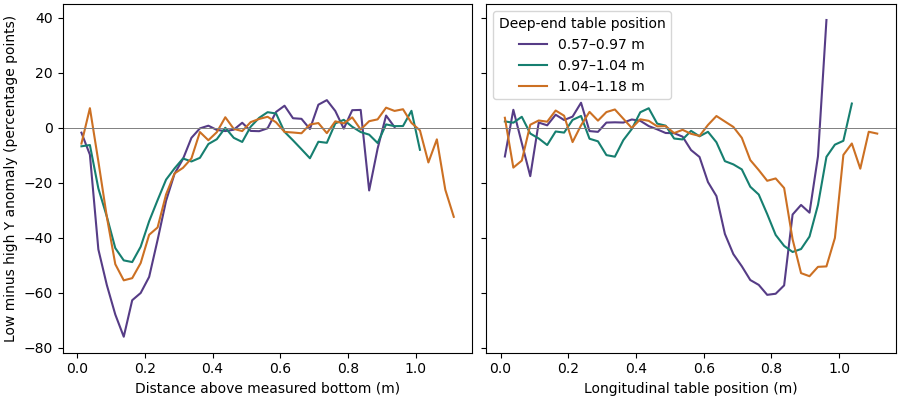

In [6]:
# Separate placements to see whether the anomaly moves on the table.
end = audit.groupby('section').deep_table_mm.median()/1000
groups = pd.qcut(end,3,labels=['short reach','middle reach','long reach'])
fig,axes = plt.subplots(1,2,figsize=(9,4),sharey=True,layout='constrained')
for ax,key in zip(axes,['bottom','table']):
    for group,color in zip(groups.cat.categories,['#563c86','#167f70','#cc7023']):
        sections = groups.index[groups==group]
        g = stack(paired.reset_index().query('section in @sections'),key,[]).groupby('position').anomaly.agg(['mean','count'])
        g = g[g['count']>=8]
        ax.plot(g.index,g['mean'],color=color,label=f'{end[sections].min():.2f}–{end[sections].max():.2f} m')
    ax.axhline(0,color='0.5',lw=.7)
    ax.set_xlabel(coords[key][0])
axes[0].set_ylabel('Low minus high Y anomaly (percentage points)')
axes[1].legend(title='Deep-end table position')
fig.savefig(figdir/'placement_comparison.png',dpi=180)
plt.show()